In [85]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict , Annotated
from pydantic import BaseModel, Field
import os
import operator


In [86]:
# api_key = os.environ.get("OPENROUTER_API_KEY")
api_key = os.getenv("OPENROUTER_API_KEY")


llm = ChatOpenAI(
      model="openrouter/free",
       base_url="https://openrouter.ai" + "/api/v1",
       api_key=api_key,
       temperature=0.2,
       max_tokens=4000,
       max_retries=3,
)

In [87]:
class EvaluationSchema(TypedDict):
    feedback: str = Field(description="Feedback on the essay")
    score: int = Field(description="Score out of 10 for the essay",ge=0,le=0)
    

In [88]:
structured_output = llm.with_structured_output(EvaluationSchema)

In [89]:
essay="""# Technology: Good Servant, Dangerous Master

### Introduction

Technology is a powerful tool that accelerates human progress. However, if left unchecked, it can easily shift from serving humanity to controlling it.

### 1. Technology as a Good Servant (Benefits)

* **Governance:** Digital tools like digital identity and unified payments improve public service delivery and reduce corruption.
* **Economy:** Boosts productivity and gives small businesses and farmers real-time market access.
* **Education & Health:** Telemedicine and digital learning platforms bridge geographical divides.

### 2. Technology as a Dangerous Master (Risks)

* **Privacy Loss:** Algorithms harvest data and manipulate individual behavior.
* **Social Impact:** Social media fuels polarization, addiction, and mental fatigue.
* **Job Disruption:** Rapid automation threatens traditional jobs and widens the digital divide.

### 3. The Way Forward

* Enforce strict ethical AI designs and data privacy laws.
* Bridge the digital and cognitive divide through education.
* Keep human oversight central to critical decisions.

### Conclusion

Technology is neutral; it reflects human choices. We must maintain moral leadership over our inventions to ensure technology remains a tool for human welfare."""

In [90]:
essay_prompt = f"""Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}
"""

In [91]:
# output = llm.invoke(essay_prompt).content
# output2 = structured_output.invoke(essay_prompt)


# print("Feedback:", output)
# print("Structured Feedback:", output2)

In [92]:
class UPSCState(TypedDict):
    feedback:str
    score:int
    essay:str
    language_feedback:str
    analysis_feedback:str #Doa
    clearity_feedback:str # Cot
    overall_feedback:str
    individual_scores: Annotated[list[int], operator.add] # reducer function to merge the scores



In [93]:
def language_feedback(state: UPSCState):
    structured_llm = llm.with_structured_output(EvaluationSchema)
    prompt = f"Evaluate the language quality of the following essay:\n{state['essay']}"
    result = structured_llm.invoke(prompt)
    return {
        "language_feedback": result.feedback,
        "individual_scores": [result.score]
    }

def analysis_feedback(state: UPSCState):
    structured_llm = llm.with_structured_output(EvaluationSchema)
    prompt = f"Evaluate the analysis quality (multi-dimensional depth) of the following essay:\n{state['essay']}"
    result = structured_llm.invoke(prompt)
    return {
        "analysis_feedback": result.feedback,
        "individual_scores": [result.score]
    }

def clearity_feedback(state: UPSCState):
    structured_llm = llm.with_structured_output(EvaluationSchema)
    prompt = f"Evaluate the clarity and structure of the following essay:\n{state['essay']}"
    result = structured_llm.invoke(prompt)
    return {
        "clearity_feedback": result.feedback,
        "individual_scores": [result.score]
    }

def individual_scores(state: UPSCState):
    scores = state['individual_scores']
    total_score = sum(scores)
    avg_score = total_score / len(scores) if scores else 0.0
    return {
        "score": total_score,
        "avg_score": avg_score
    }

In [94]:
# 5. Build StateGraph & Compile Workflow
graph = StateGraph(UPSCState)

graph.add_node("language_feedback", language_feedback)
graph.add_node("analysis_feedback", analysis_feedback)
graph.add_node("clearity_feedback", clearity_feedback)
graph.add_node("individual_scores", individual_scores)

# Parallel execution edges from START
graph.add_edge(START, "language_feedback")
graph.add_edge(START, "analysis_feedback")
graph.add_edge(START, "clearity_feedback")

# Converge into individual_scores node
graph.add_edge("language_feedback", "individual_scores")
graph.add_edge("analysis_feedback", "individual_scores")
graph.add_edge("clearity_feedback", "individual_scores")

graph.add_edge("individual_scores", END)

workflow = graph.compile()

In [95]:
mock_essay = """
Technology is a good servant, but a dangerous master. 
It drives innovation and development, but can also cause isolation and job loss if left unchecked.
"""

result = workflow.invoke({
    "essay": mock_essay,
    "language_feedback": "",
    "analysis_feedback": "",
    "clearity_feedback": "",
    "overall_feedback": "",
    "individual_scores": [],
    "score": 0,
    "avg_score": 0.0
})

print(result)

AttributeError: 'dict' object has no attribute 'feedback'

In [ ]:
print(result["individual_scores"])

['# Language Quality Evaluation\n\n## Overall Assessment\n\nThe essay demonstrates **solid foundational language skills** but remains quite underdeveloped for what is presented as an essay.\n\n## Strengths\n\n- **Grammar:** Both sentences are grammatically correct, with proper punctuation and sentence structure.\n- **Parallel structure:** The essay uses a nice balanced contrast — "drives... but can also cause..."\n- **Clarity:** The meaning is communicated clearly and concisely.\n- **Cohesion:** The two sentences connect logically, moving from a general statement to supporting ideas.\n\n## Weaknesses\n\n- **Extremely brief:** Only two sentences — lacks development, examples, or elaboration.\n- **No original expression:** The opening line is a well-known aphorism (Alfred North Whitehead), so the author\'s own voice is minimal.\n- **Limited vocabulary range:** Words like "good," "dangerous," "innovation" are adequate but basic.\n- **No conclusion:** The essay ends abruptly without wrappi

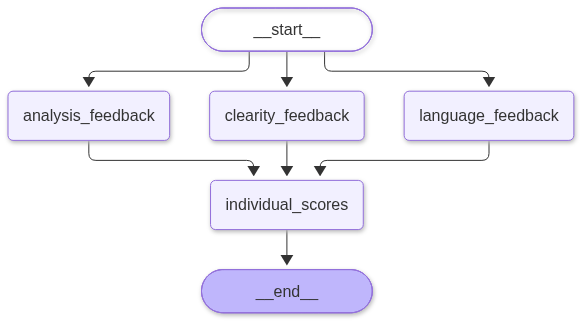

In [ ]:
from IPython.display import display, Markdown , Image
# display(Markdown("### Output of the workflow execution  Bmi: {}".format(output["bmi"])))

Image(workflow.get_graph().draw_mermaid_png())